## 1. Chuẩn hóa & Tổng hợp Metrics (`evaluation_results.csv`)

Cell code bên dưới thực hiện thu thập kết quả đánh giá của cả ba mô hình từ thư mục `results/metrics/`, chuẩn hóa về cùng một định dạng 9 chỉ số chung và xuất ra file tổng hợp cuối cùng:

- **Dữ liệu đầu vào (`results/metrics/`):**
  - `baseline_metrics.csv` (TF-IDF + Logistic Regression)
  - `frozen_encoder_metrics.csv` (DistilBERT Frozen Encoder)
  - `fine_tuning_metrics.csv` (DistilBERT Fine-Tuning)
- **Tệp kết quả đầu ra:** `results/metrics/evaluation_results.csv` *(tệp này nằm trong danh sách loại trừ của `.gitignore` nên sẽ tự động được sinh ra cục bộ trên máy khi chạy cell code bên dưới)*.

,Model,Accuracy,Precision,Recall,Macro F1-score,Training Time (s),Inference Time (s),Trainable Parameters,Model Size (MB)
0,baseline,0.919605,0.919489,0.919605,0.919449,11.716433,0.238444,200004,3.408733
1,frozen_encoder,0.902895,0.902938,0.902895,0.902787,1038.145755,60.591762,3076,253.169937
2,fine_tuning,0.942237,0.942432,0.942237,0.942283,2353.081307,16.669674,66365956,253.169937


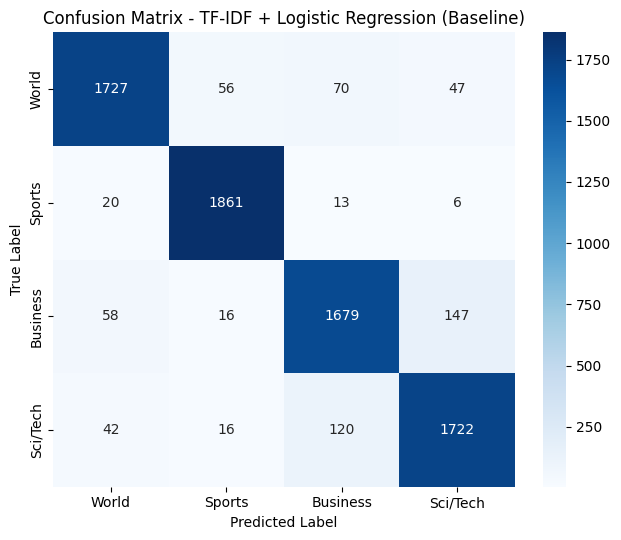

Đã lưu: /Users/xuanmai/Downloads/Course-Work-6-main/results/figures/confusion_matrix_baseline.png


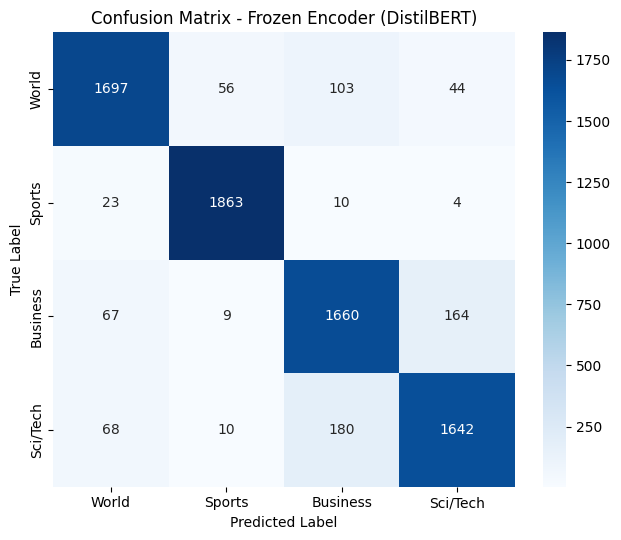

Đã lưu: /Users/xuanmai/Downloads/Course-Work-6-main/results/figures/confusion_matrix_frozen_encoder.png
Đang chờ file predictions: fine_tuning_predictions.csv


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

ROOT = Path("..").resolve() if Path.cwd().name == "notebooks" else Path(".").resolve()
METRICS_DIR = ROOT / "results" / "metrics"
FIGURES_DIR = ROOT / "results" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

LABEL_NAMES = ["World", "Sports", "Business", "Sci/Tech"]

# 1. Chọn đúng 9 cột chuẩn chung từ các file metrics và đổi tên đẹp cho bảng báo cáo
COLS_TO_KEEP = [
    "model",
    "accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro",
    "train_time_s",
    "inference_time_s",
    "trainable_params",
    "model_size_mb",
]

RENAME_TO_DISPLAY = {
    "model": "Model",
    "accuracy": "Accuracy",
    "precision_macro": "Precision",
    "recall_macro": "Recall",
    "f1_macro": "Macro F1-score",
    "train_time_s": "Training Time (s)",
    "inference_time_s": "Inference Time (s)",
    "trainable_params": "Trainable Parameters",
    "model_size_mb": "Model Size (MB)",
}

metric_files = [
    METRICS_DIR / "baseline_metrics.csv",
    METRICS_DIR / "frozen_encoder_metrics.csv",
    METRICS_DIR / "fine_tuning_metrics.csv",
]

frames = []
for f in metric_files:
    if f.exists():
        df = pd.read_csv(f)[COLS_TO_KEEP].rename(columns=RENAME_TO_DISPLAY)
        frames.append(df)
    else:
        print(f"Đang chờ file: {f.name}")

if frames:
    eval_df = pd.concat(frames, ignore_index=True)
    eval_df.to_csv(METRICS_DIR / "evaluation_results.csv", index=False)
    display(eval_df)

# 2. Vẽ, lưu và hiển thị Confusion Matrix từ các file predictions
pred_configs = [
    ("TF-IDF + Logistic Regression (Baseline)", METRICS_DIR / "baseline_predictions.csv", FIGURES_DIR / "confusion_matrix_baseline.png"),
    ("Frozen Encoder (DistilBERT)", METRICS_DIR / "frozen_encoder_predictions.csv", FIGURES_DIR / "confusion_matrix_frozen_encoder.png"),
    ("Fine-Tuning (DistilBERT)", METRICS_DIR / "fine_tuning_predictions.csv", FIGURES_DIR / "confusion_matrix_fine_tuning.png"),
]

for title, pred_path, fig_path in pred_configs:
    if pred_path.exists():
        df_pred = pd.read_csv(pred_path)
        cm = confusion_matrix(df_pred["true_label"], df_pred["pred_label"])
        plt.figure(figsize=(6.5, 5.5))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES)
        plt.title(f"Confusion Matrix - {title}")
        plt.xlabel("Predicted Label")
        plt.ylabel("True Label")
        plt.tight_layout()
        plt.savefig(fig_path, dpi=300)
        plt.show()
        print(f"Đã lưu: {fig_path}")
    else:
        print(f"Đang chờ file predictions: {pred_path.name}")

## 2. Biểu đồ So sánh Hiệu năng và Chi phí Tính toán

Trực quan hóa sự đánh đổi (trade-off) giữa chất lượng phân loại (**Accuracy, Precision, Recall, Macro F1-score**) và chi phí tài nguyên (**Training Time, Inference Time, Trainable Parameters, Model Size**) giữa 3 phương pháp tiếp cận.

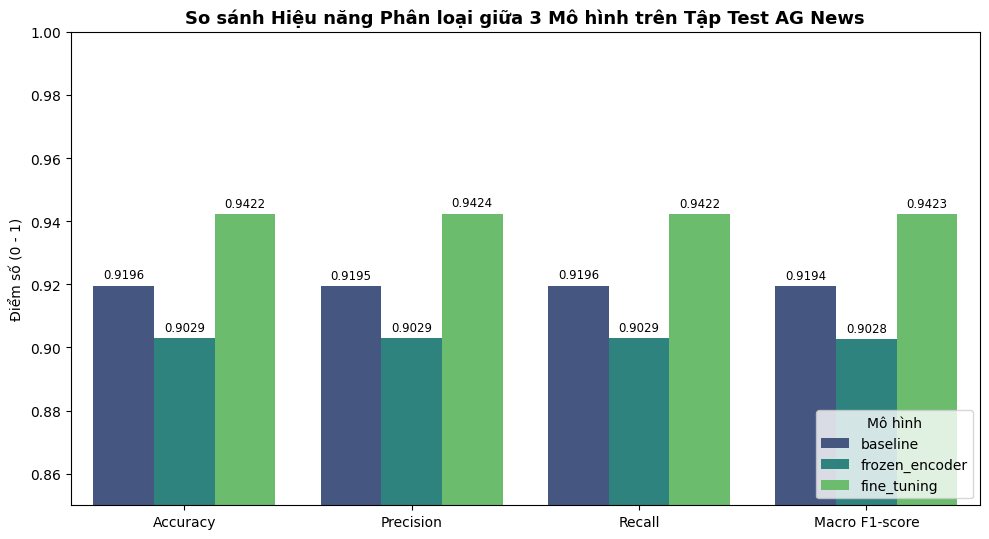

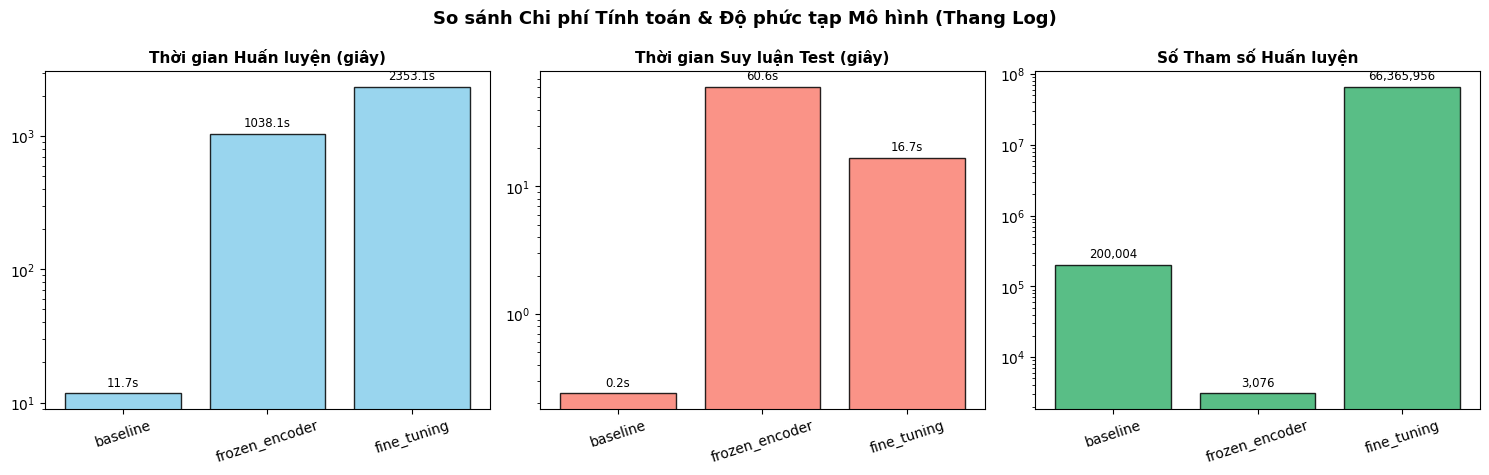

In [2]:
# Biểu đồ 2A: So sánh 4 chỉ số chất lượng phân loại (Accuracy, Precision, Recall, Macro F1)
quality_cols = ["Accuracy", "Precision", "Recall", "Macro F1-score"]
df_melted = eval_df.melt(id_vars="Model", value_vars=quality_cols, var_name="Metric", value_name="Score")

plt.figure(figsize=(10, 5.5))
ax = sns.barplot(data=df_melted, x="Metric", y="Score", hue="Model", palette="viridis")
plt.ylim(0.85, 1.0)
plt.title("So sánh Hiệu năng Phân loại giữa 3 Mô hình trên Tập Test AG News", fontsize=13, fontweight="bold")
plt.ylabel("Điểm số (0 - 1)")
plt.xlabel("")
plt.legend(title="Mô hình", loc="lower right")
for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", fontsize=8.5, padding=3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "comparison_classification_metrics.png", dpi=300)
plt.show()

# Biểu đồ 2B: So sánh Thời gian Huấn luyện, Thời gian Suy luận và Số Tham số Huấn luyện
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

resource_specs = [
    ("Training Time (s)", "Thời gian Huấn luyện (giây)", "skyblue"),
    ("Inference Time (s)", "Thời gian Suy luận Test (giây)", "salmon"),
    ("Trainable Parameters", "Số Tham số Huấn luyện", "mediumseagreen"),
]

for ax, (col, title, color) in zip(axes, resource_specs):
    bars = ax.bar(eval_df["Model"], eval_df[col], color=color, edgecolor="black", alpha=0.85)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.tick_params(axis="x", rotation=18)
    ax.set_yscale("log")  # Dùng thang log để hiển thị rõ sự chênh lệch lớn giữa TF-IDF và DistilBERT
    for bar in bars:
        val = bar.get_height()
        label = f"{int(val):,}" if col == "Trainable Parameters" else f"{val:.1f}s"
        ax.annotate(label, (bar.get_x() + bar.get_width() / 2, val),
                    ha="center", va="bottom", fontsize=8.5, xytext=(0, 3), textcoords="offset points")

plt.suptitle("So sánh Chi phí Tính toán & Độ phức tạp Mô hình (Thang Log)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "comparison_computational_cost.png", dpi=300)
plt.show()

## 3. Phân tích Lỗi sai Chi tiết (Error Analysis)

Đánh giá chi tiết Precision/Recall/F1 trên từng nhãn (**World, Sports, Business, Sci/Tech**), xác định cặp nhãn dễ bị nhầm lẫn nhất và trích xuất các mẫu dự đoán sai điển hình để lý giải nguyên nhân.

In [3]:
# 1. In Classification Report chi tiết từng lớp cho cả 3 mô hình
for title, pred_path, _ in pred_configs:
    if pred_path.exists():
        df_p = pd.read_csv(pred_path)
        print("=" * 70)
        print(f"CLASSIFICATION REPORT: {title}")
        print("=" * 70)
        print(classification_report(df_p["true_label"], df_p["pred_label"], target_names=LABEL_NAMES, digits=4))

# 2. Phân tích cặp nhãn nhầm lẫn nhiều nhất & ví dụ lỗi sai trên mô hình tốt nhất (Fine-Tuning)
ft_pred_path = METRICS_DIR / "fine_tuning_predictions.csv"
if ft_pred_path.exists():
    df_ft = pd.read_csv(ft_pred_path)
    df_ft["true_name"] = df_ft["true_label"].map(lambda i: LABEL_NAMES[i])
    df_ft["pred_name"] = df_ft["pred_label"].map(lambda i: LABEL_NAMES[i])
    
    errors = df_ft[df_ft["true_label"] != df_ft["pred_label"]].copy()
    print(f"\nTổng số mẫu dự đoán sai của Fine-Tuning: {len(errors)} / {len(df_ft)} ({len(errors)/len(df_ft)*100:.2f}%)")
    
    # Thống kê top các cặp nhầm lẫn phổ biến nhất
    confusion_pairs = (
        errors.groupby(["true_name", "pred_name"])
        .size()
        .reset_index(name="Count")
        .sort_values("Count", ascending=False)
    )
    print("\nTop các cặp nhãn bị nhầm lẫn nhiều nhất (Fine-Tuning):")
    display(confusion_pairs)

    # Hiển thị 10 mẫu văn bản dự đoán sai điển hình (nếu file predictions có cột text)
    text_col = next((c for c in ["text", "sentence", "input_text", "title"] if c in errors.columns), None)
    if text_col:
        print("\nMột số mẫu tin tức bị phân loại nhầm điển hình:")
        display(errors[[text_col, "true_name", "pred_name"]].head(10))

CLASSIFICATION REPORT: TF-IDF + Logistic Regression (Baseline)
              precision    recall  f1-score   support

       World     0.9350    0.9089    0.9218      1900
      Sports     0.9548    0.9795    0.9670      1900
    Business     0.8921    0.8837    0.8879      1900
    Sci/Tech     0.8959    0.9063    0.9011      1900

    accuracy                         0.9196      7600
   macro avg     0.9195    0.9196    0.9194      7600
weighted avg     0.9195    0.9196    0.9194      7600

CLASSIFICATION REPORT: Frozen Encoder (DistilBERT)
              precision    recall  f1-score   support

       World     0.9148    0.8932    0.9039      1900
      Sports     0.9613    0.9805    0.9708      1900
    Business     0.8500    0.8737    0.8617      1900
    Sci/Tech     0.8857    0.8642    0.8748      1900

    accuracy                         0.9029      7600
   macro avg     0.9029    0.9029    0.9028      7600
weighted avg     0.9029    0.9029    0.9028      7600



## 4. Evaluation → Interpretation và Error Analysis → Decision
(Bản đầy đủ có số liệu kiểm tra lại được: `docs/results/decision_log.md` mục 3–5; tái tạo bằng `python src/analyze_decisions.py`.)

### Interpretation (Evaluation)
- **Fine-Tuning > Baseline > Frozen Encoder** trên mọi chỉ số chất lượng (Accuracy 0,9422 / 0,9204 / 0,9034). Test cân bằng 1.900 mẫu/lớp nên Accuracy ≈ Recall trung bình ≈ Macro F1; sai số 95% của Accuracy ≈ ±0,6 điểm %, vậy các chênh 2,2 và 1,7 điểm % là chênh lệch thật.
- **Precision/Recall theo lớp:** Business và Sci/Tech khó nhất ở cả ba mô hình (Frozen Business precision chỉ 0,846: cứ ~6–7 dự đoán Business thì 1 sai). Sports dễ nhất (F1 0,967–0,987).
- **Cùng backbone**, mở khóa encoder đem lại +3,9 điểm % (0,9034 → 0,9422).
- **Không so sánh thời gian giữa các thiết bị:** Baseline/Frozen chạy CPU, Fine-Tuning chạy CUDA. Không được kết luận Fine-Tuning huấn luyện nhanh hơn Frozen.

### Decision (Error Analysis)
- Lỗi Business ↔ Sci/Tech: Baseline 260 → Fine-Tuning 243 (**−6,5%**), trong khi lỗi ở các cặp khác giảm 43% (345 → 196); tỉ trọng của cặp này tăng từ 43% lên **55%** tổng lỗi.
- **Quyết định:** coi phần lớn lỗi Business ↔ Sci/Tech là giới hạn dữ liệu (chủ đề giao nhau, 9 cặp văn bản trùng nhưng khác nhãn trong train), không đầu tư thêm kiến trúc cho riêng cặp này; kiểm tra thủ công ≥ 100 mẫu để xác nhận; không dùng confidence để tự động chấp nhận (112/163 lỗi của Baseline/Frozen có tin cậy > 0,9).
- **Mô hình cuối (đề xuất):** Fine-Tuning; Baseline là phương án dự phòng cho CPU; Frozen Encoder không được chọn (kém hơn Baseline và đắt hơn).
